## A test trial for numerous data generation

In [1]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = False
rgb = False

# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])


from TimeSformer.VDT_cat_vm import VDT_cat
from DDIM.ddim import remove_module_prefix
nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 200
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False



cuda:0
metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
metadata exists in: dataset/2024-10-31_xacti_5fps/test/metadata_40.pkl


load model: success
metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
1386 26 dataset/2024-10-31_xacti_5fps/train/2 copy/5.mp4
li:0.181 ang:0.000
li:0.342 ang:0.000
li:0.215 ang:0.000
li:0.040 ang:-0.200
li:0.024 ang:-0.400
li:0.065 ang:-0.400
li:0.027 ang:-0.400
li:0.016 ang:-0.400
li:0.028 ang:-0.400
li:0.042 ang:-0.400
li:0.029 ang:-0.400
li:0.001 ang:-0.400
li:0.031 ang:-0.400
li:0.001 ang:-0.400
li:0.001 ang:-0.400
li:0.025 ang:-0.400
li:0.038 ang:-0.400
li:0.022 ang:-0.400
li:0.064 ang:-0.400
li:0.017 ang:-0.400
li:0.016 ang:0.000
li:0.003 ang:0.000
li:0.015 ang:0.000
li:0.018 ang:0.000
li:0.060 ang:0.000
li:0.190 ang:0.000
li:0.141 ang:0.000
li:0.163 ang:0.000
li:0.185 ang:0.000
li:0.157 ang:0.000
li:0.181 ang:0.000
li:0.342 ang:0.000
li:0.215 ang:0.000
li:0.040 ang:-0.200
li:0.024 ang:-0.400
li:0.065 ang:-0.400
li:0.027 ang:-0.400
li:0.016 ang:-0.400
li:0.028 ang:-0.400
li:0.042 ang:-0.400
li:0.029 ang:-0.400
li:0.001 ang:-0.400
li:0.031 ang:-0.400
li:0.00

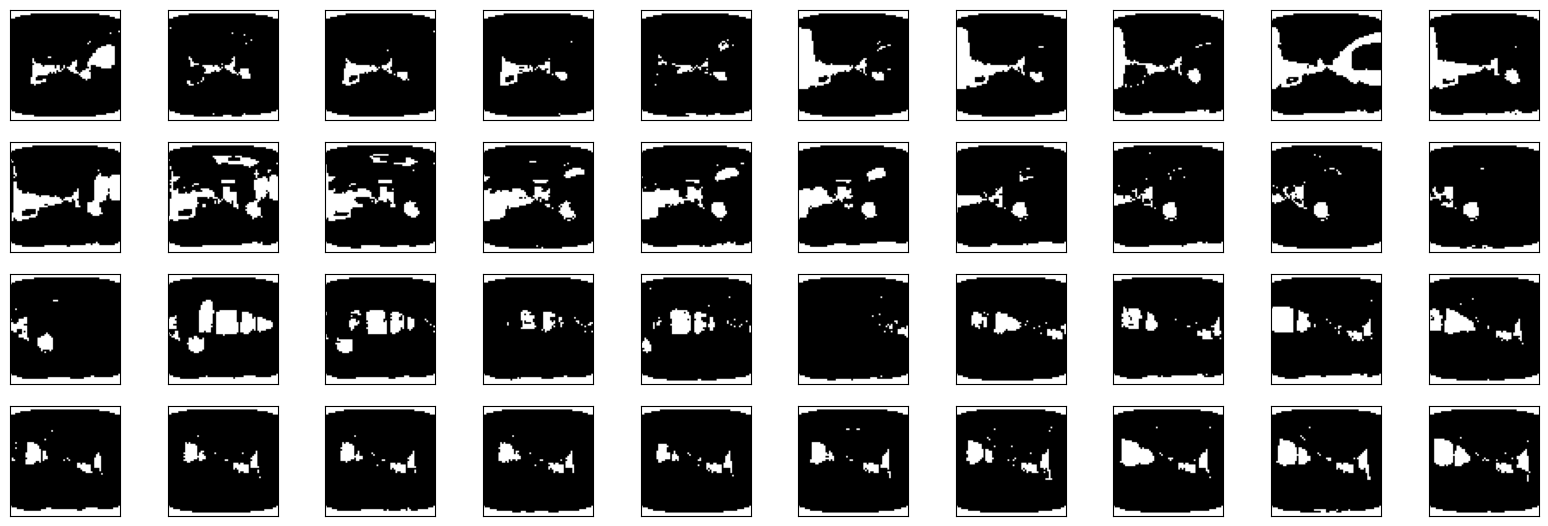

<Figure size 2000x500 with 0 Axes>

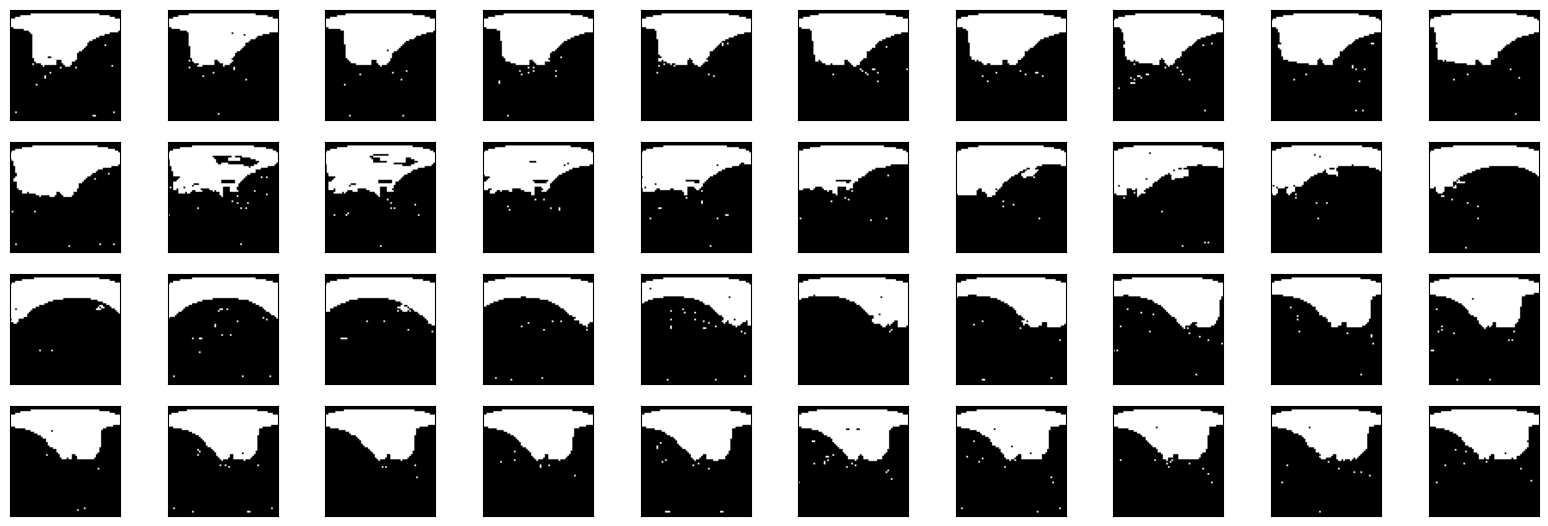

<Figure size 2000x500 with 0 Axes>

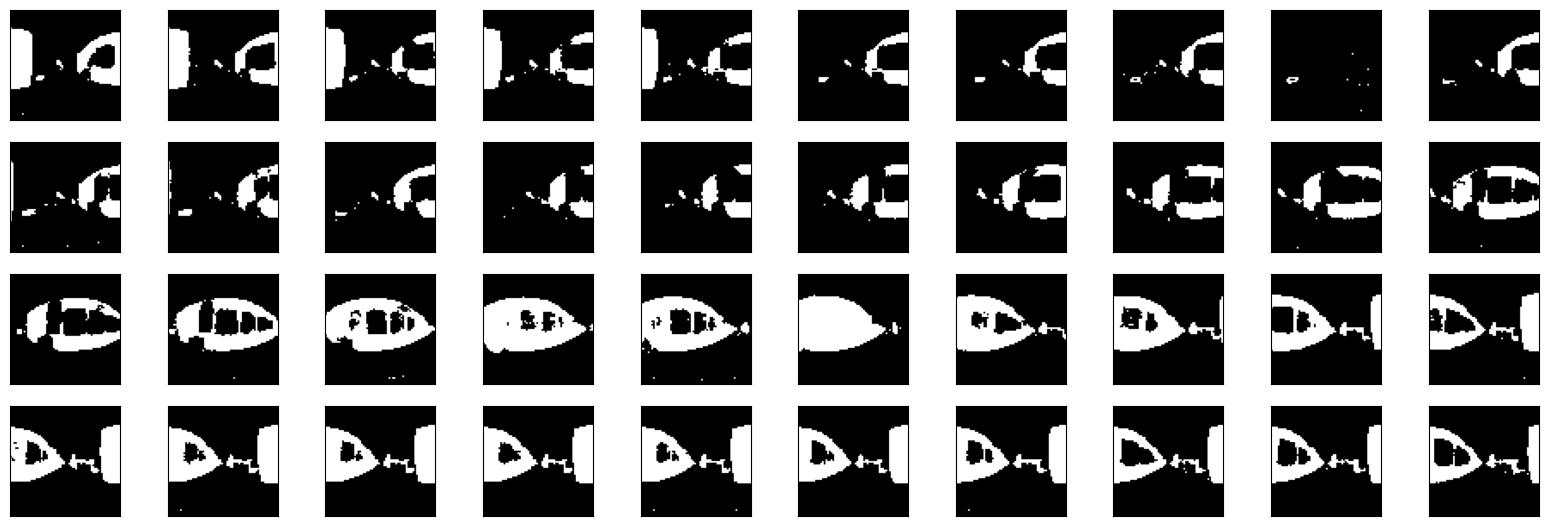

<Figure size 2000x500 with 0 Axes>

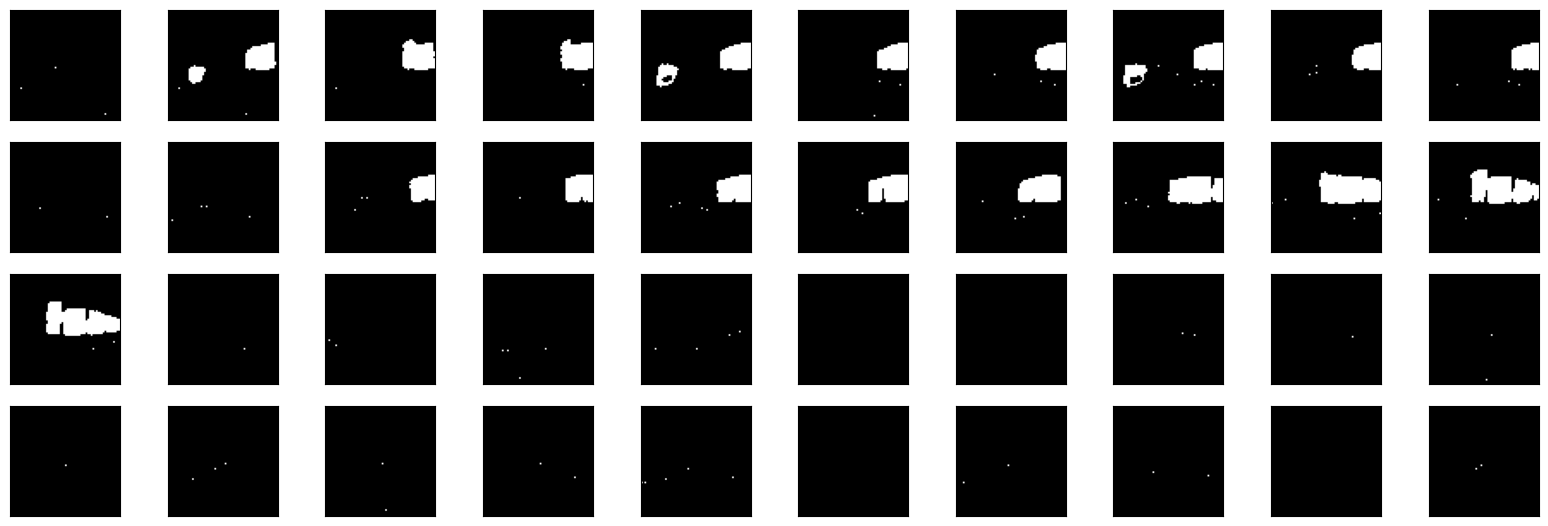

<Figure size 2000x500 with 0 Axes>

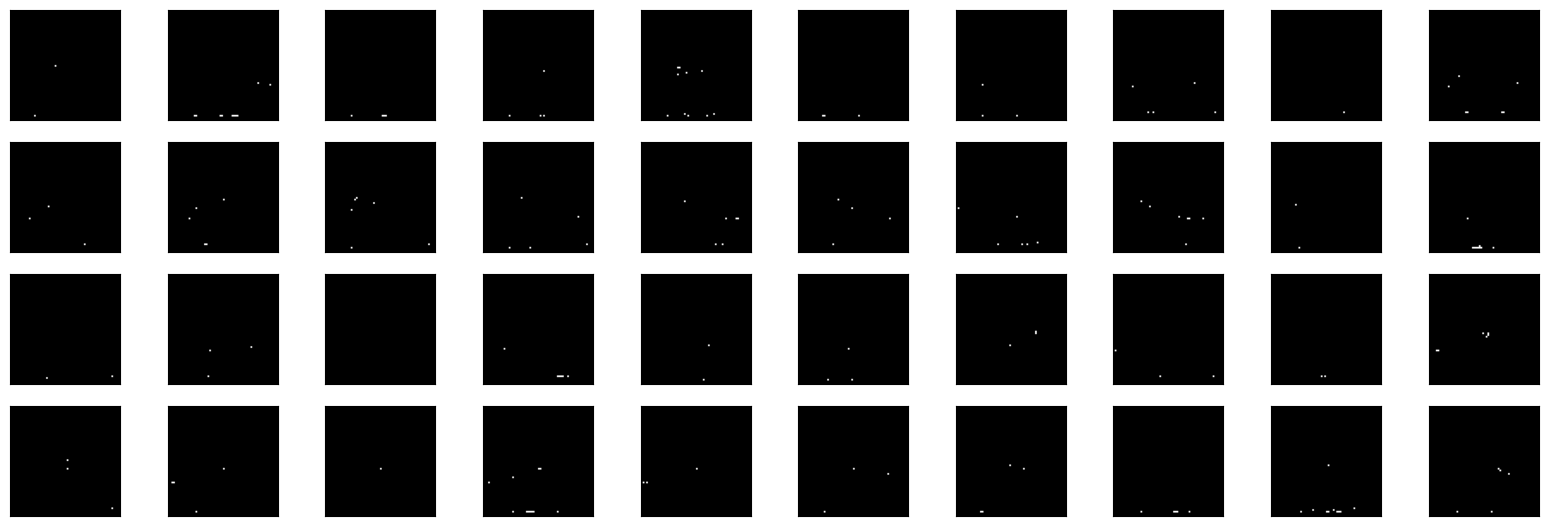

<Figure size 2000x500 with 0 Axes>

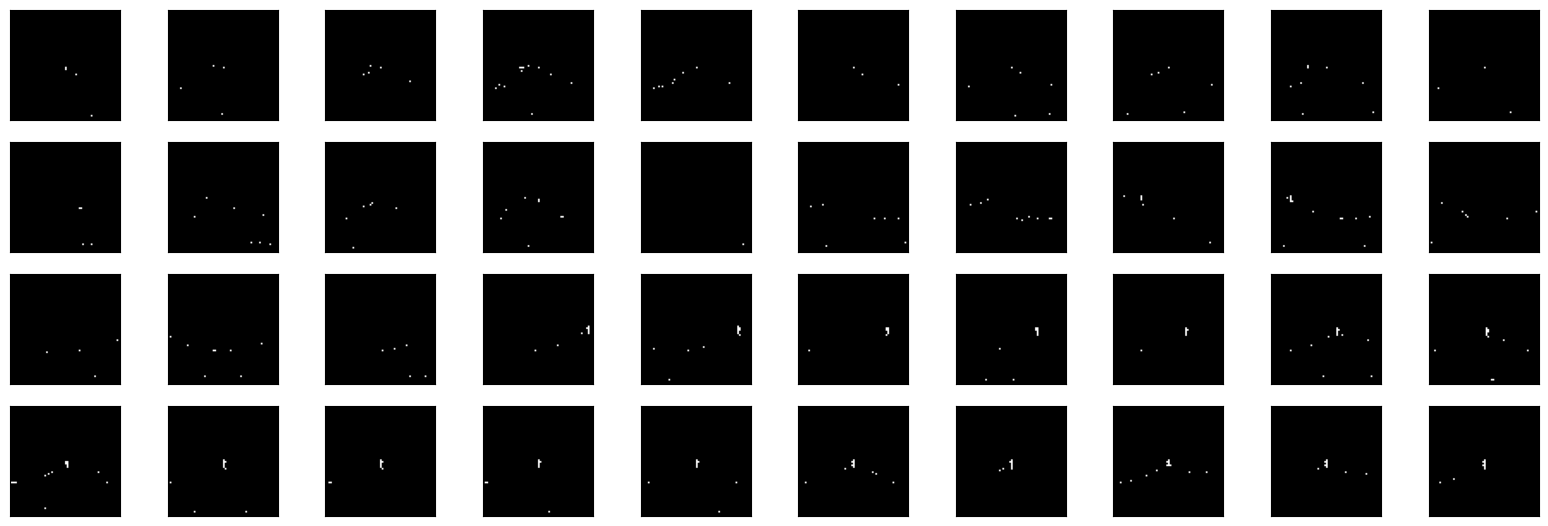

<Figure size 2000x500 with 0 Axes>

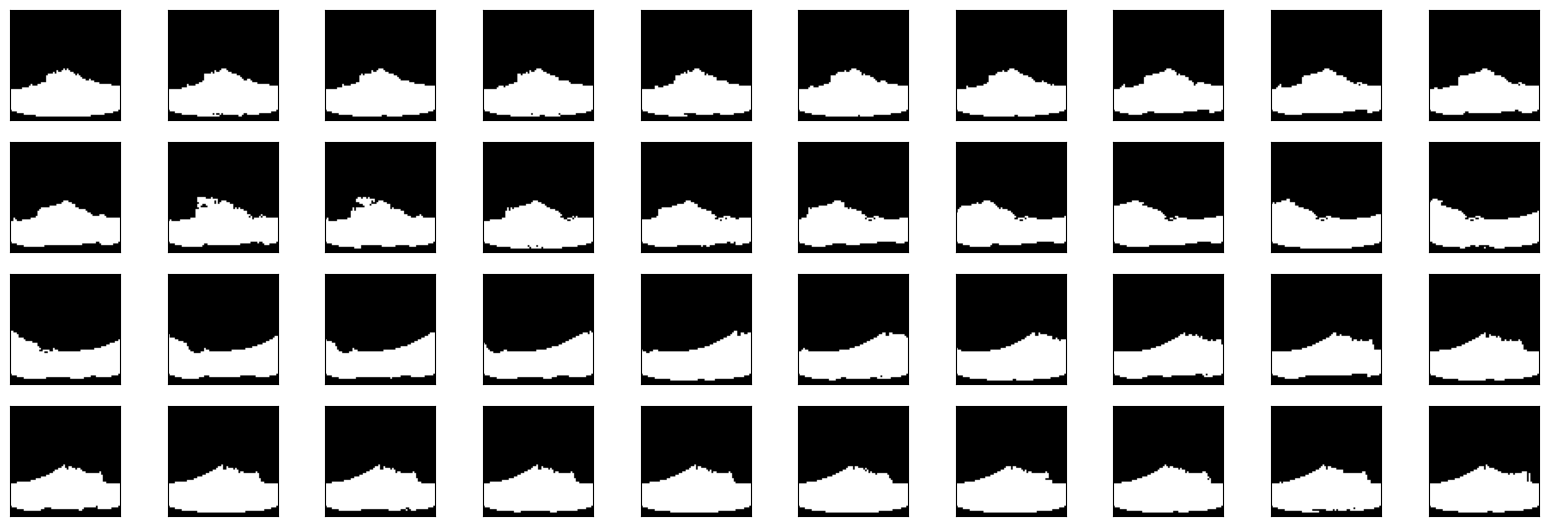

<Figure size 2000x500 with 0 Axes>

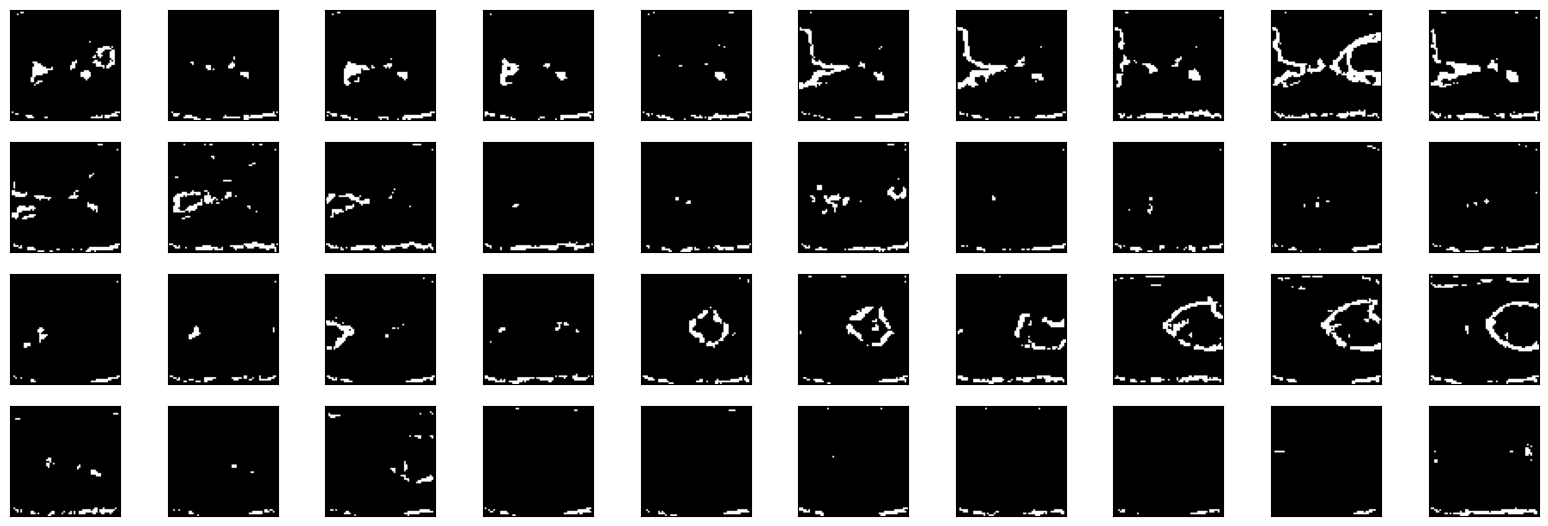

<Figure size 2000x500 with 0 Axes>

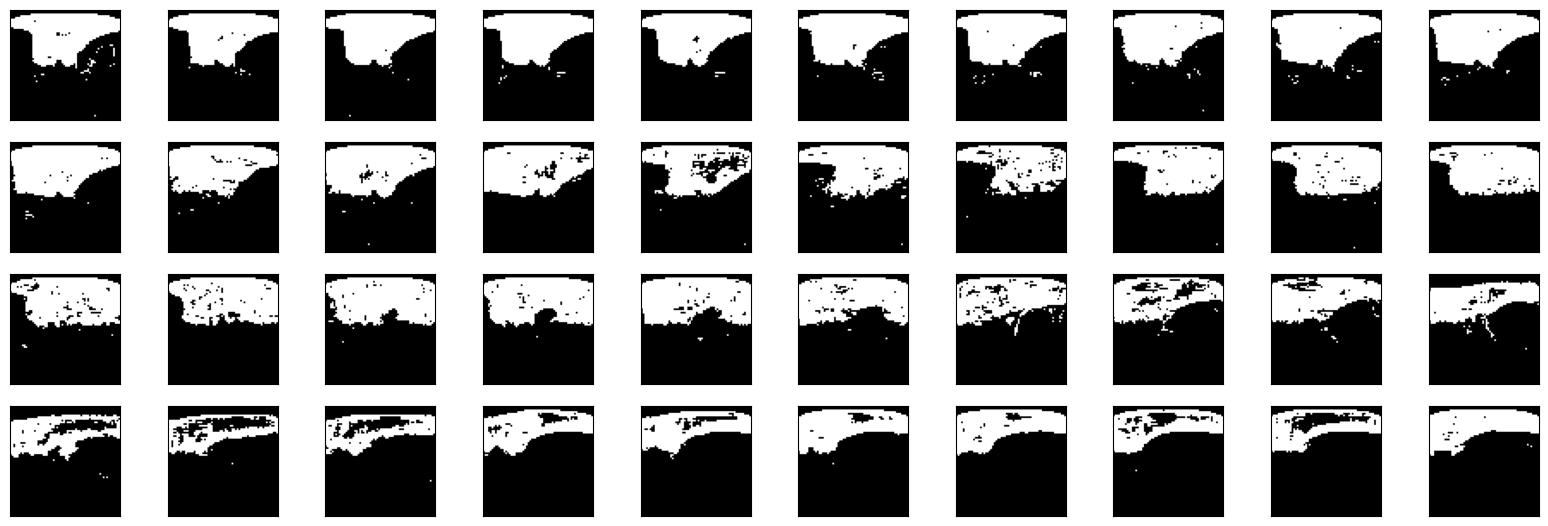

<Figure size 2000x500 with 0 Axes>

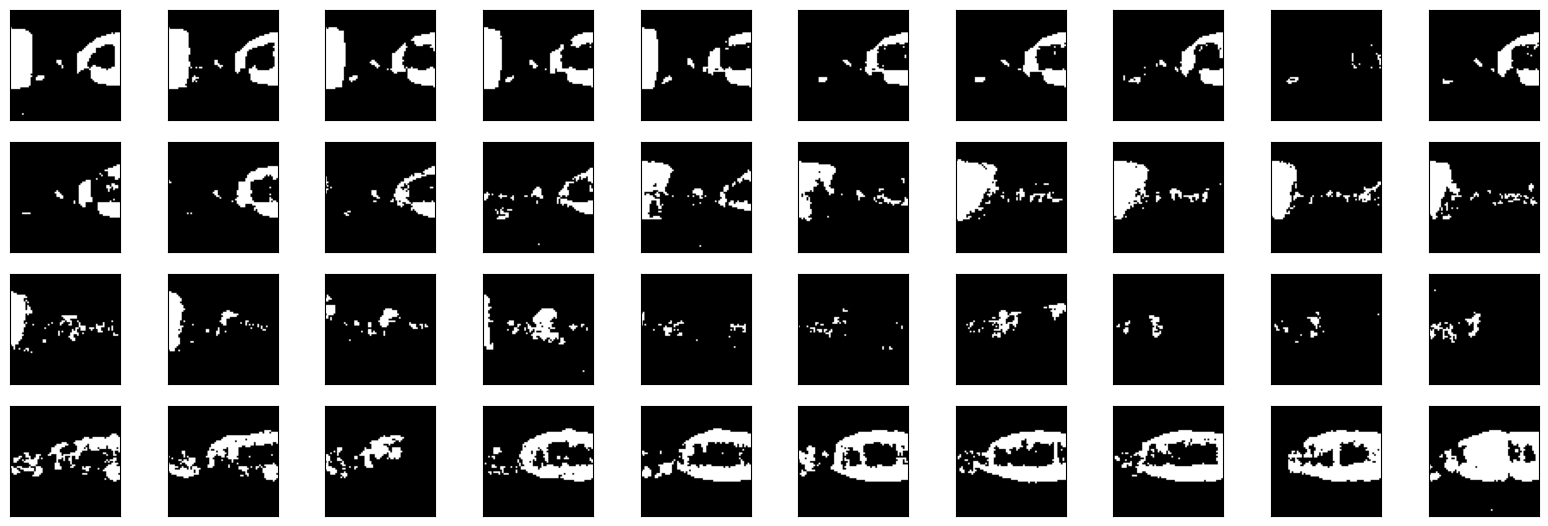

<Figure size 2000x500 with 0 Axes>

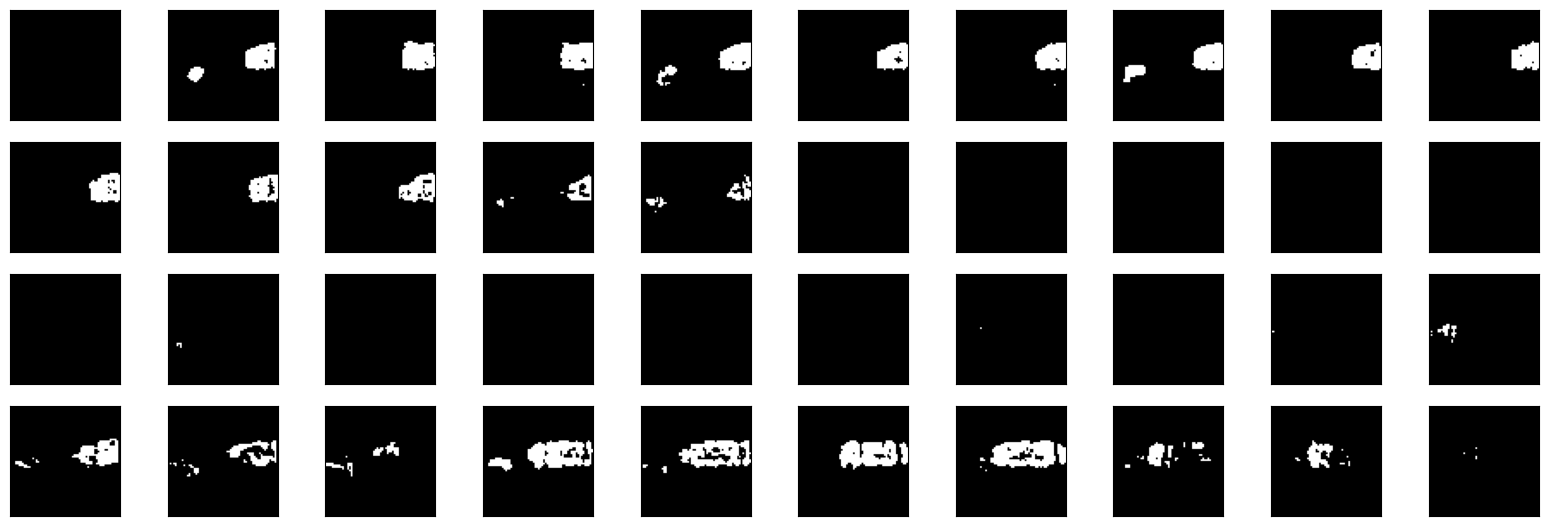

<Figure size 2000x500 with 0 Axes>

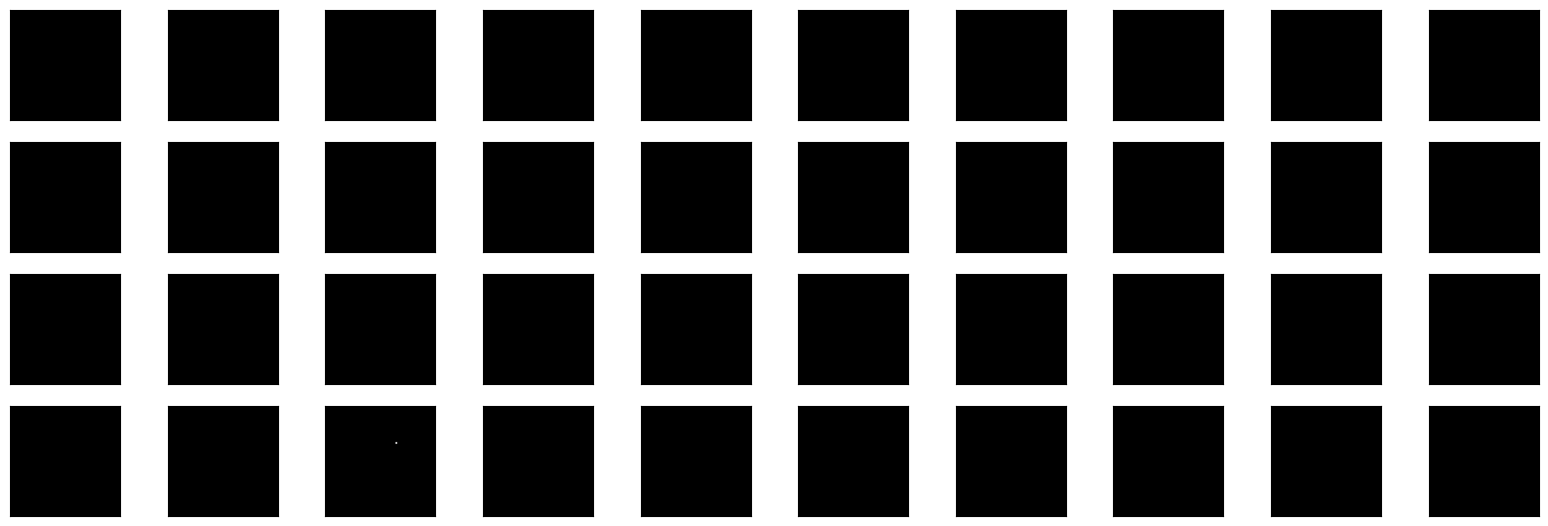

<Figure size 2000x500 with 0 Axes>

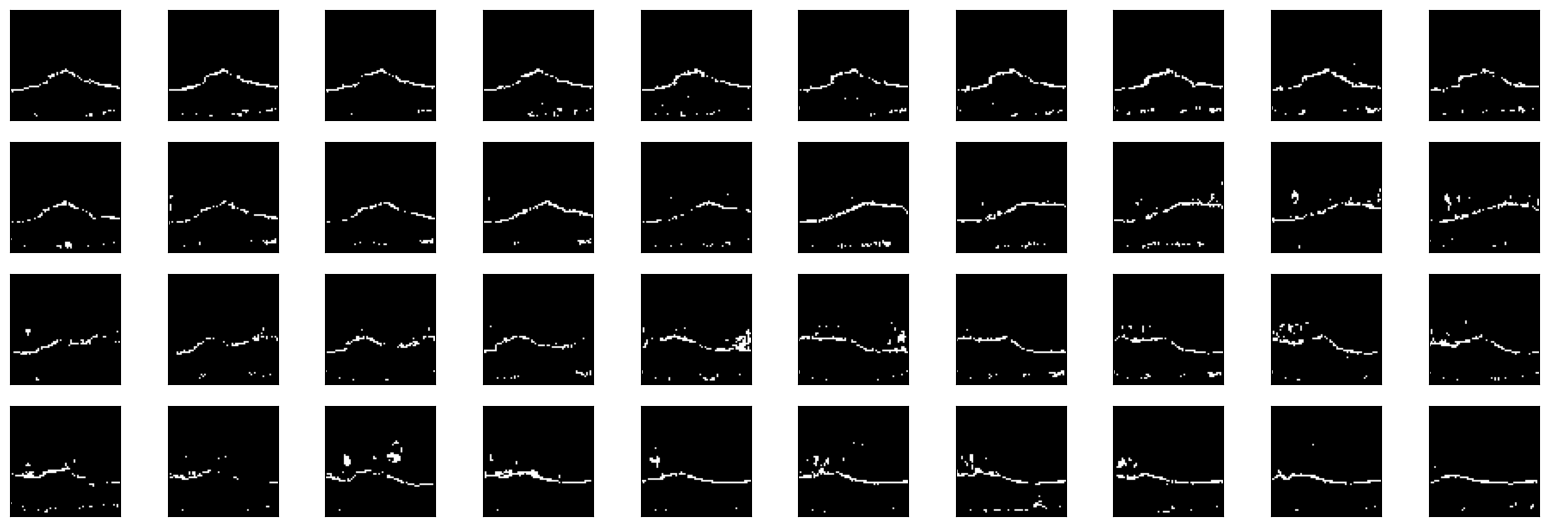

<Figure size 2000x500 with 0 Axes>

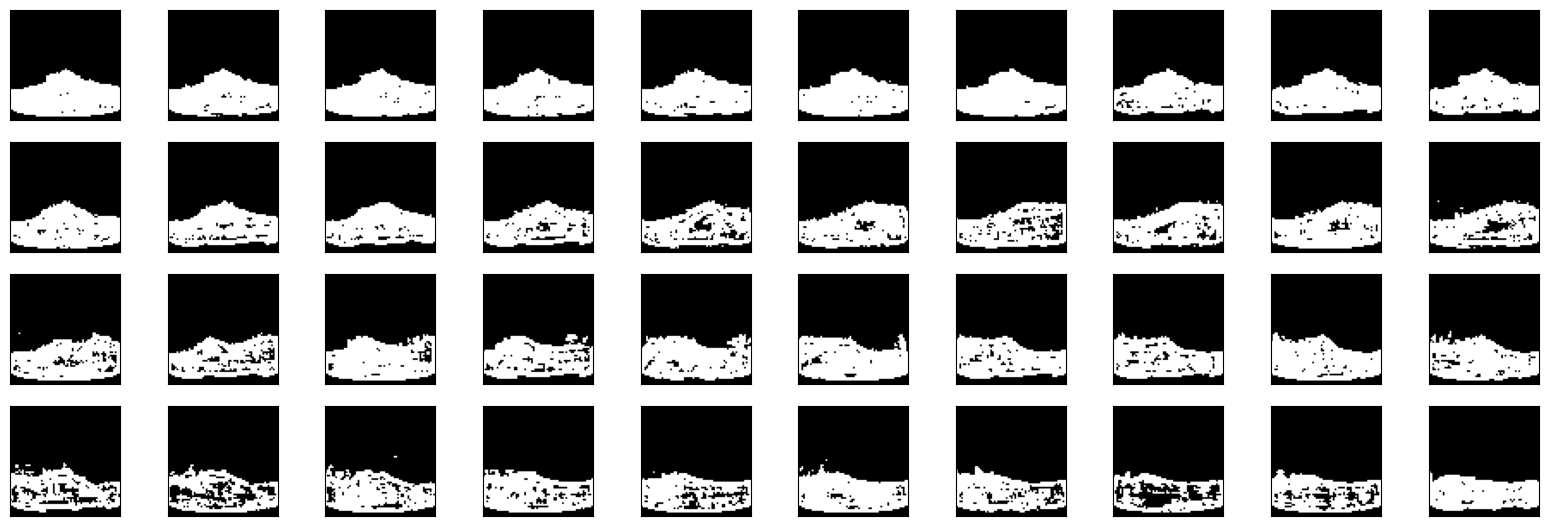

<Figure size 2000x500 with 0 Axes>

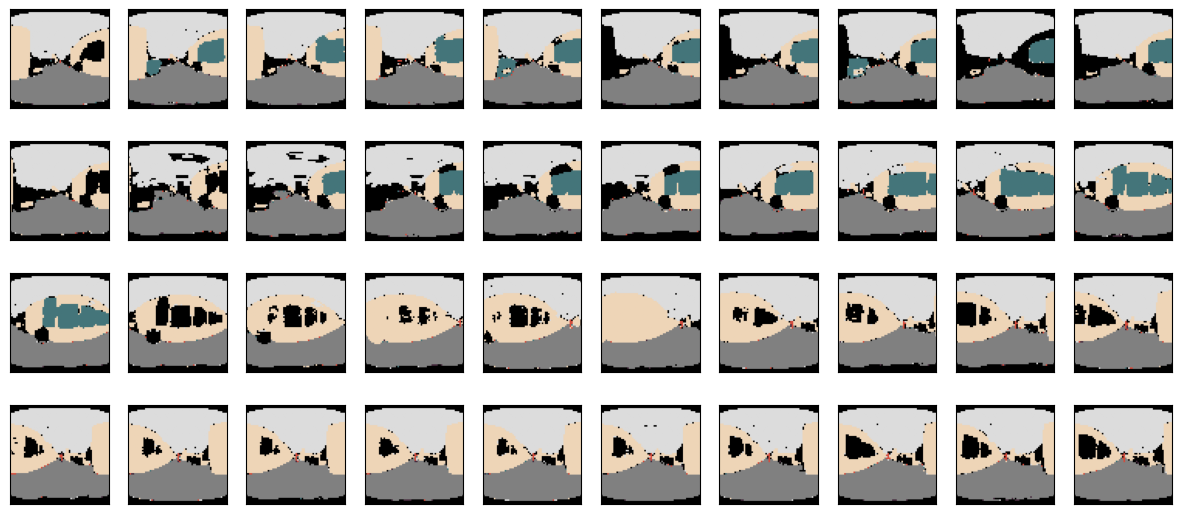

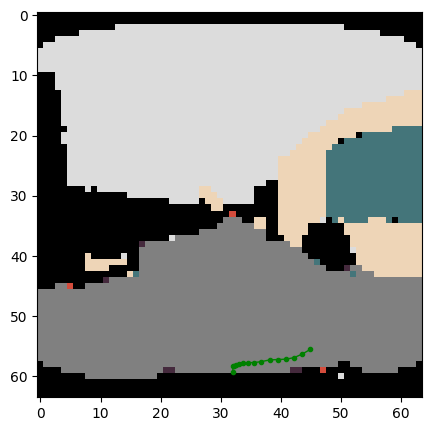

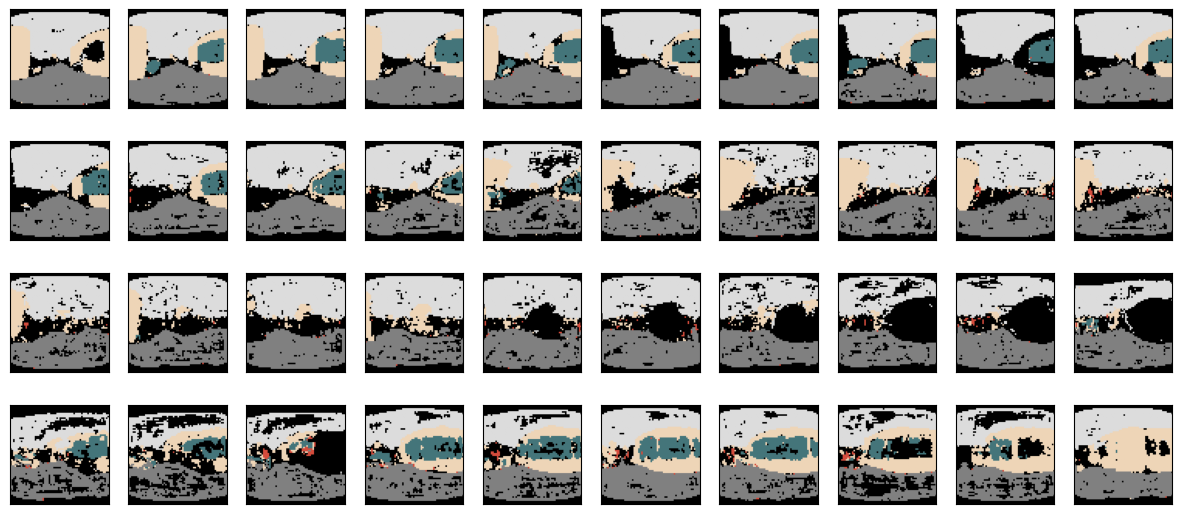

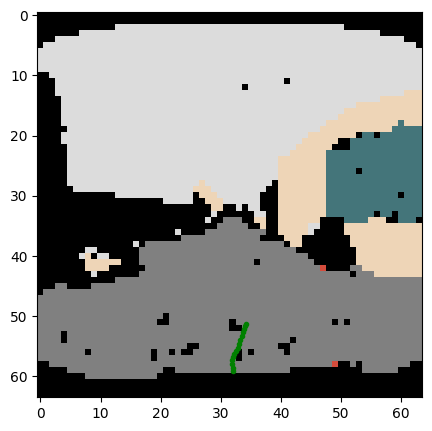

In [3]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time
from eval.utils import manhattan_dist
import random

all_manhattan_distance = []

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 1)
for real_idx in real_data_random_indices:
    # real_idx = 12872, 11189, 19614, 1386
    real_idx = 1386
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 1 # The number of multiple predictions
    frame_t = 10 

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(real_idx, vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = batch.permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(batch.permute(0,2,3,1))

    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))
    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    rec_vid_list.append(batch_rgb.permute(0,2,3,1))  
    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)


    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
        
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i]) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))

        if rgb:
            dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        else:
            dec_rgb = gray2color(dec_vid)
            dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        rec_vid_list.append(dec_rgb)
   
    #undetected_obs, ceiling, wall, detected_furniture, door, Human, Floor
    vis_list = [True, True, True, True, True, True, True]
    manhattan_distance, video_list = manhattan_dist(args, dec_vid_list[:], rec_mot_list[:], frame_t, input_dim, vis_list = vis_list)
    # all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
# torch.save(all_manhattan_distance, 'eval/all_generated_manhattan_distances_500x50.pt')

for t in range(pred_num+1):
    # print(video_list[t].shape)
    end_x,end_y = visual_vid_mmot(video_list[t], [rec_mot_list[t]], rgb=True, is_road=True, grid=False, frame_t=frame_t)

